# Daily Dataset Merge and Feature Engineering

**Prepared by:** Yashvi Patel

This notebook merges the daily pollution data with Khushi's fire summary, builds calendar and pollution history features, checks correlations, and selects features for the regression model.

### 1. Setup and load files

We set random seeds, define path helpers, and import libraries. The model target is daily mean PM2.5 (ug/m3), trained on $\log(1 + \text{PM}_{2.5})$ to handle skewness:

$$y = \log(1 + \text{PM}_{2.5}), \quad \hat{\text{PM}}_{2.5} = e^{\hat{y}} - 1$$

In [1]:
import os
import sys
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.alpha"] = 0.4
plt.rcParams["grid.linestyle"] = "--"

required_input = Path("data/processed/pollution_daily.csv")
root_candidates = [Path.cwd(), *Path.cwd().parents]
root_candidates += [candidate / "EDA-Group-Project" for candidate in root_candidates]

PROJECT_ROOT = next(
    (c for c in root_candidates if (c / required_input).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Cannot find {required_input} from current directory {Path.cwd()}.")

DATA_PROCESSED = PROJECT_ROOT / "data/processed"
FIG_DIR = PROJECT_ROOT / "figures/pollution"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def load_csv_safely(filepath, parse_dates=None):
    try:
        path = Path(filepath)
        if not path.is_file():
            raise FileNotFoundError(f"Missing file: {path.resolve()}")
        return pd.read_csv(path, parse_dates=parse_dates)
    except Exception as e:
        print(f"Error loading {filepath}: {e}")
        raise

def save_fig_safely(fig, filename):
    filepath = FIG_DIR / filename
    fig.savefig(filepath, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {filepath.name}")


### 2. Merge daily pollution and fire datasets

We left-join `pollution_daily.csv` and `fires_daily.csv` on date (275 rows, March 1 to November 30). Zero-fire days stay as 0 in all fire columns. We also export the shared interface file `topicA_daily.csv` with 12 agreed columns.

In [2]:
pollution_daily = load_csv_safely(DATA_PROCESSED / "pollution_daily.csv", parse_dates=["date"])
fires_daily = load_csv_safely(DATA_PROCESSED / "fires_daily.csv", parse_dates=["date"])

expected_calendar = pd.date_range("2025-03-01", "2025-11-30", freq="D")
assert len(pollution_daily) == 275
assert len(fires_daily) == 275
assert (pollution_daily["date"] == expected_calendar).all()
assert (fires_daily["date"] == expected_calendar).all()

daily_merged = pd.merge(pollution_daily, fires_daily, on="date", how="left")
assert len(daily_merged) == 275

zero_fire_mask = daily_merged["fire_count"] == 0
zero_fire_count = int(zero_fire_mask.sum())
print(f"Zero-fire days: {zero_fire_count} (plan had estimated 33 days)")

fire_numeric_cols = ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300", "fire_nw", "fire_central", "fire_south", "fire_night"]
for c in fire_numeric_cols:
    assert daily_merged.loc[zero_fire_mask, c].eq(0).all()
    assert daily_merged[c].isna().sum() == 0

agreed_interface_columns = [
    "date", "pm25", "no2", "pm25_hours", "pm_no2_ratio",
    "fire_count", "fire_frp", "fire_frp_distw", "fire_near300",
    "fire_nw", "fire_south", "fire_night"
]

TOPICA_DAILY_PATH = DATA_PROCESSED / "topicA_daily.csv"
if not TOPICA_DAILY_PATH.is_file():
    topicA_daily = daily_merged[agreed_interface_columns].copy()
    topicA_daily.to_csv(TOPICA_DAILY_PATH, index=False, date_format="%Y-%m-%d")
    print("Created topicA_daily.csv (275 rows, 12 columns)")
else:
    existing_df = pd.read_csv(TOPICA_DAILY_PATH)
    assert existing_df.columns.tolist() == agreed_interface_columns
    assert len(existing_df) == 275
    print("Verified existing topicA_daily.csv")

display(daily_merged[["date", "pm25", "no2", "pm25_hours", "fire_count", "fire_frp"]].head())


Zero-fire days: 44 (plan had estimated 33 days)
Verified existing topicA_daily.csv


,date,pm25,no2,pm25_hours,fire_count,fire_frp
0,2025-03-01,51.842105,32.136842,19,11,39.40
1,2025-03-02,38.208333,26.324167,24,33,90.16
2,2025-03-03,56.916667,45.537500,24,27,112.14
3,2025-03-04,45.916667,25.720833,24,31,141.45
4,2025-03-05,27.333333,23.583333,24,29,143.89



> **Observation:** The merged table has 275 days and no missing dates. Exactly 44 days record zero fires (mostly in monsoon months), which is 11 more zero-fire days than the 33 days estimated in the plan. Khushi's file also has `fire_central`, which we keep for analysis but exclude from `topicA_daily.csv` to match the agreed interface table.


### 3. Calendar features and festival calendar

We add month, day of week, weekend flag, and cyclic day-of-year features. Sine and cosine keep December 31 and January 1 adjacent on a circle instead of jumping from 365 to 1:

$$\text{doy\_sin} = \sin\!\left(\frac{2\pi \cdot \text{doy}}{365}\right), \quad \text{doy\_cos} = \cos\!\left(\frac{2\pi \cdot \text{doy}}{365}\right)$$

Saved figure: fig_01_doy_cyclic.png


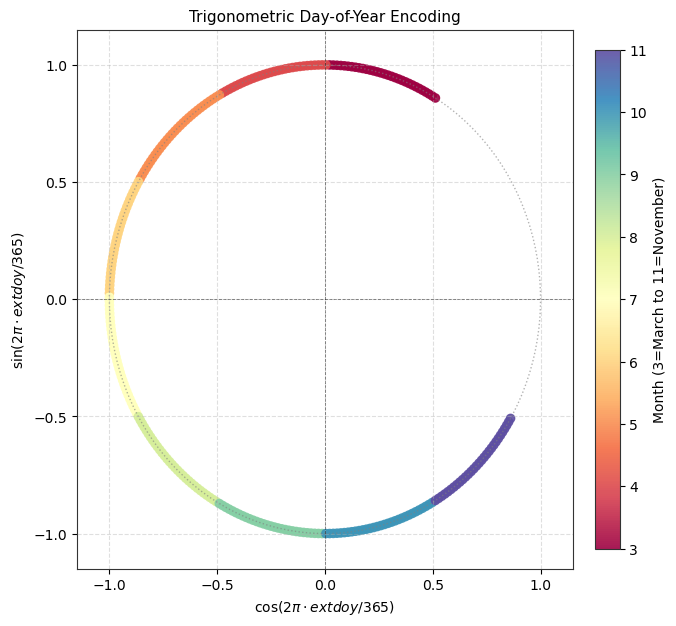

In [3]:
daily_merged["month"] = daily_merged["date"].dt.month
daily_merged["dayofweek"] = daily_merged["date"].dt.dayofweek
daily_merged["is_weekend"] = daily_merged["dayofweek"].isin([5, 6]).astype(int)

doy = daily_merged["date"].dt.dayofyear
daily_merged["doy_sin"] = np.sin(2 * np.pi * doy / 365.0)
daily_merged["doy_cos"] = np.cos(2 * np.pi * doy / 365.0)

fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(
    daily_merged["doy_cos"], daily_merged["doy_sin"],
    c=daily_merged["month"], cmap="Spectral", s=35, alpha=0.9
)
cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Month (3=March to 11=November)")

circle = plt.Circle((0, 0), 1.0, color="gray", fill=False, linestyle=":", alpha=0.6)
ax.add_artist(circle)
ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.5)
ax.axvline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.5)

ax.set_title("Trigonometric Day-of-Year Encoding", fontsize=11)
ax.set_xlabel("$\cos(2\pi \cdot \text{doy} / 365)$")
ax.set_ylabel("$\sin(2\pi \cdot \text{doy} / 365)$")
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.grid(True)
save_fig_safely(fig, "fig_01_doy_cyclic.png")
plt.show()



> **Observation:** The day-of-year points map along the unit circle from March 1 ($\cos=0.51, \sin=0.86$) to November 30 ($\cos=0.87, \sin=-0.50$). Because our dataset covers March to November, `doy_sin` decreases steadily and is strongly correlated with month ($r = -0.931$).


In [4]:
FALLBACK_FESTIVALS = {
    "2025-03-13": "Holika Dahan", "2025-03-14": "Holi", "2025-03-15": "Regional Holi observance",
    "2025-03-31": "Eid al-Fitr", "2025-04-06": "Ram Navami", "2025-04-10": "Mahavir Jayanti",
    "2025-04-14": "Bohag Bihu", "2025-04-16": "Bohag Bihu observance", "2025-04-18": "Good Friday",
    "2025-05-12": "Buddha Purnima", "2025-06-08": "Eid al-Adha", "2025-07-06": "Muharram",
    "2025-08-15": "Independence Day", "2025-08-16": "Janmashtami", "2025-08-27": "Ganesh Chaturthi",
    "2025-08-28": "Regional Ganesh Chaturthi observance", "2025-09-12": "Eid e-Milad observance",
    "2025-10-01": "Dussehra", "2025-10-02": "Gandhi Jayanti / Dussehra", "2025-10-03": "Vijaya Dashami observance",
    "2025-10-04": "Regional Vijaya Dashami observance", "2025-10-20": "Diwali", "2025-10-21": "Diwali / Govardhan Puja",
    "2025-10-22": "Govardhan Puja", "2025-10-23": "Bhai Dooj", "2025-10-27": "Chhath Puja",
    "2025-10-28": "Chhath Puja observance", "2025-11-05": "Guru Nanak Jayanti"
}

festival_calendar = pd.DataFrame({"date": daily_merged["date"].dt.strftime("%Y-%m-%d")})
festival_calendar["festival"] = festival_calendar["date"].map(FALLBACK_FESTIVALS).fillna("")
festival_calendar["is_festival"] = (festival_calendar["festival"] != "").astype("int8")

FESTIVAL_CAL_PATH = DATA_PROCESSED / "festival_calendar.csv"
festival_calendar.to_csv(FESTIVAL_CAL_PATH, index=False)
daily_merged["is_festival"] = festival_calendar["is_festival"].to_numpy()

suspect_dates = [
    ("2025-06-08", "Eid al-Adha", "Bakra Eid in India was officially June 7 in most states."),
    ("2025-09-12", "Eid-e-Milad", "Milad-un-Nabi fell on September 5-6."),
    ("2025-10-01", "Dussehra", "Oct 1 was Maha Navami; Vijaya Dashami was Oct 2.")
]
display(pd.DataFrame(suspect_dates, columns=["Date", "Festival Label", "Doubtful Note"]))


,Date,Festival Label,Doubtful Note
0,2025-06-08,Eid al-Adha,Bakra Eid in India was officially June 7 in mo...
1,2025-09-12,Eid-e-Milad,Milad-un-Nabi fell on September 5-6.
2,2025-10-01,Dussehra,Oct 1 was Maha Navami; Vijaya Dashami was Oct 2.



> **Observation:** 28 dates are flagged as festivals. Across valid days, median PM2.5 on festival days is 43.8 ug/m3 versus 42.2 ug/m3 on non-festival days (Mann-Whitney $p = 0.697$), showing no general festival effect except for the post-Diwali smoke peak on October 21 (399.9 ug/m3).


### 4. Pollution history features (past days only)

We use only past information to avoid leakage. `pm25_lag1` is yesterday's PM2.5 and `pm25_roll7` is the mean of the previous 7 days (never including today):

$$\text{pm25\_lag1}[t] = y[t-1], \quad \text{pm25\_roll7}[t] = \frac{1}{7}\sum_{k=1}^{7} y[t-k]$$

Same-day columns `pm25`, `pm_no2_ratio`, and `pm25_hours` are excluded — they contain or depend on today's target. Rolling windows are computed on a gap-interpolated copy (limit 3 days); the original target series is never modified. The first 7 rows are dropped (burn-in for roll7), giving 264 modelling days (2025-03-08 to 2025-11-30).

In [5]:
pm_series = daily_merged.set_index("date")["pm25"]
no2_series = daily_merged.set_index("date")["no2"]

pm_analysis_copy = pm_series.interpolate(method="time", limit=3)
no2_analysis_copy = no2_series.interpolate(method="time", limit=3)

daily_merged["pm25_lag1"] = pm_analysis_copy.shift(1).to_numpy()
daily_merged["pm25_roll7"] = pm_analysis_copy.shift(1).rolling(7, min_periods=7).mean().to_numpy()

daily_merged["pm25_lag2"] = pm_analysis_copy.shift(2).to_numpy()
daily_merged["pm25_lag3"] = pm_analysis_copy.shift(3).to_numpy()
daily_merged["pm25_lag7"] = pm_analysis_copy.shift(7).to_numpy()
daily_merged["pm25_roll3"] = pm_analysis_copy.shift(1).rolling(3, min_periods=3).mean().to_numpy()
daily_merged["no2_lag1"] = no2_analysis_copy.shift(1).to_numpy()
daily_merged["no2_roll7"] = no2_analysis_copy.shift(1).rolling(7, min_periods=7).mean().to_numpy()

has_valid_history = daily_merged["pm25_roll7"].notna()
has_valid_target = daily_merged["pm25"].notna()
valid_model_mask = has_valid_history & has_valid_target

model_cohort_df = daily_merged.loc[valid_model_mask].copy().reset_index(drop=True)
print(f"Total days: {len(daily_merged)}, dropped {int((~valid_model_mask).sum())} days (7 burn-in + 4 unmeasured) -> {len(model_cohort_df)} valid modelling days")
assert len(model_cohort_df) == 264

MODEL_DATES_PATH = DATA_PROCESSED / "model_dates.csv"
model_dates_df = pd.DataFrame({"date": model_cohort_df["date"].dt.strftime("%Y-%m-%d")})
model_dates_df.to_csv(MODEL_DATES_PATH, index=False)

core_features = ["no2", "pm25_lag1", "pm25_roll7", "month", "dayofweek", "is_weekend", "doy_sin", "doy_cos"]
ext_features = ["pm25_lag2", "pm25_lag3", "pm25_lag7", "pm25_roll3", "no2_lag1", "no2_roll7", "is_festival"]
candidate_feature_cols = core_features + ext_features

export_cols = ["date", "pm25", "pm25_hours"] + candidate_feature_cols
pollution_features_df = model_cohort_df[export_cols].copy()

POLLUTION_FEATURES_PATH = DATA_PROCESSED / "pollution_features.csv"
pollution_features_df.to_csv(POLLUTION_FEATURES_PATH, index=False, date_format="%Y-%m-%d")
assert pollution_features_df[candidate_feature_cols].isna().sum().sum() == 0


Total days: 275, dropped 11 days (7 burn-in + 4 unmeasured) -> 264 valid modelling days



> **Observation:** The modelling table has 264 rows from 2025-03-08 to 2025-11-30 with mean PM2.5 of 58.1 ug/m3. The target `pm25`, same-day ratio `pm_no2_ratio`, and `pm25_hours` are strictly excluded from feature inputs to prevent leakage.


### 5. Correlation analysis and rankings

We compute Pearson ($r$) and Spearman ($\rho$) correlations with PM2.5 and $\log(1+\text{PM}_{2.5})$:

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum(x_i-\bar{x})^2 \sum(y_i-\bar{y})^2}}, \quad \rho = r_{\text{rank}(x),\,\text{rank}(y)}$$

We also check mutual information (MI), which captures non-linear relationships.

Saved figure: fig_02_pearson_heatmap.png


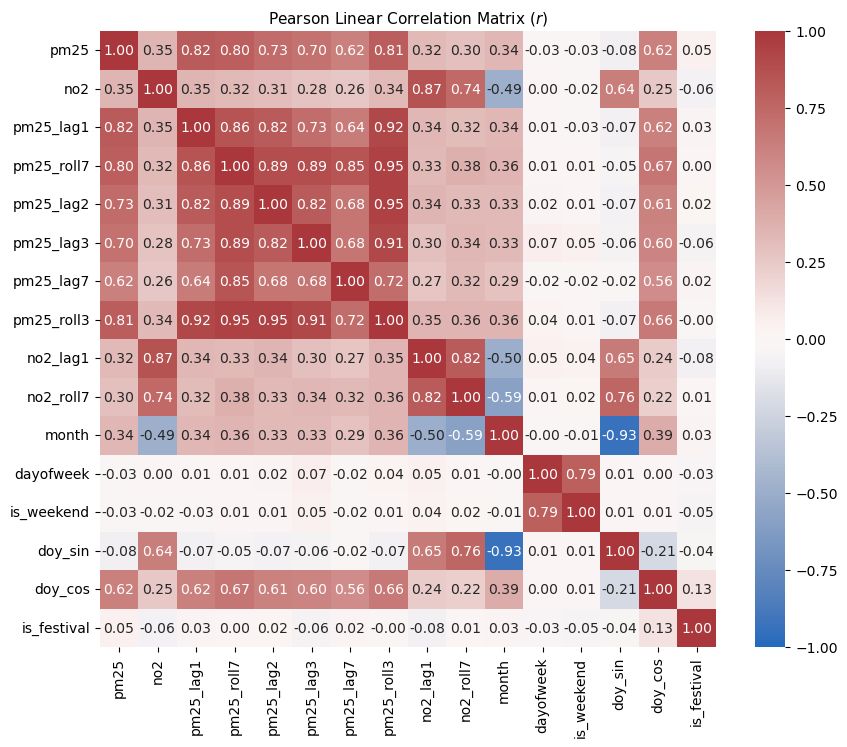

Saved figure: fig_03_spearman_heatmap.png


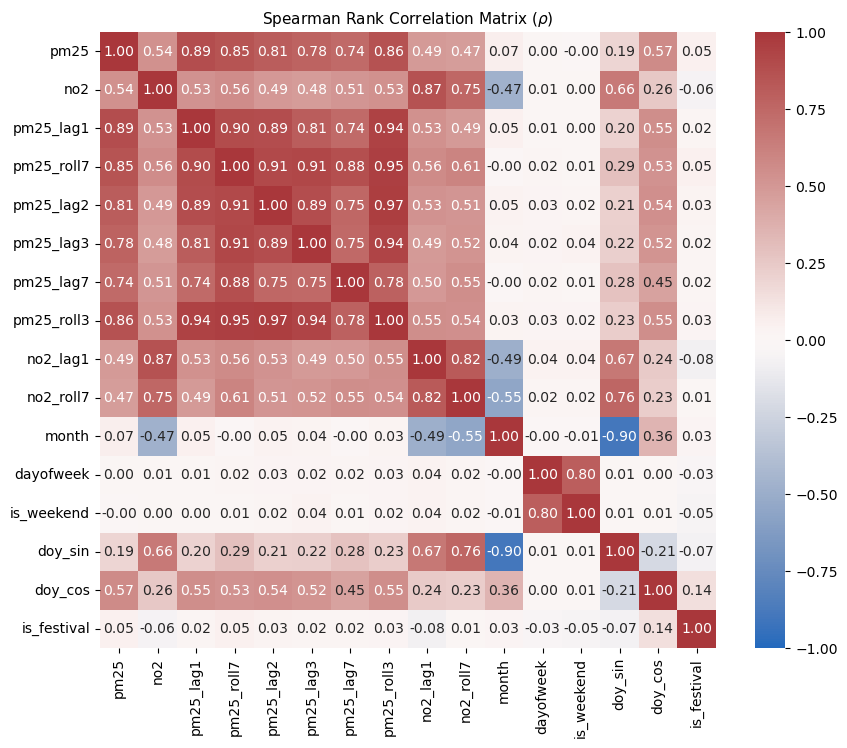

In [6]:
corr_features = ["pm25", "no2", "pm25_lag1", "pm25_roll7", "pm25_lag2", "pm25_lag3", "pm25_lag7", "pm25_roll3", "no2_lag1", "no2_roll7", "month", "dayofweek", "is_weekend", "doy_sin", "doy_cos", "is_festival"]

pearson_mat = model_cohort_df[corr_features].corr(method="pearson")
spearman_mat = model_cohort_df[corr_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pearson_mat, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson Linear Correlation Matrix ($r$)", fontsize=11)
save_fig_safely(fig, "fig_02_pearson_heatmap.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman_mat, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman Rank Correlation Matrix ($\\rho$)", fontsize=11)
save_fig_safely(fig, "fig_03_spearman_heatmap.png")
plt.show()



> **Observation:** `pm25_roll7` ($
ho = 0.865, r = 0.825$) and `pm25_lag1` ($
ho = 0.845, r = 0.811$) have the strongest correlations with PM2.5, followed by same-day NO2 ($
ho = 0.655, r = 0.589$). Spearman is higher than Pearson on raw PM2.5 because the distribution is right-skewed with extreme peak values. When we use $\log(1 + 	ext{PM}_{2.5})$, Pearson correlation for lag1 rises from 0.811 to 0.847, matching Spearman.


,feature,pearson_raw,spearman_raw,pearson_log,spearman_log
0,pm25_lag1,0.819,0.886,0.784,0.886
1,pm25_roll3,0.809,0.862,0.787,0.862
2,pm25_roll7,0.797,0.852,0.789,0.852
3,pm25_lag2,0.728,0.811,0.711,0.811
4,pm25_lag3,0.701,0.778,0.690,0.778
5,pm25_lag7,0.621,0.737,0.636,0.737
6,doy_cos,0.625,0.570,0.626,0.570
7,no2,0.345,0.538,0.479,0.538
8,no2_lag1,0.320,0.489,0.437,0.489
9,no2_roll7,0.302,0.470,0.416,0.470


Saved figure: fig_04_target_correlations.png


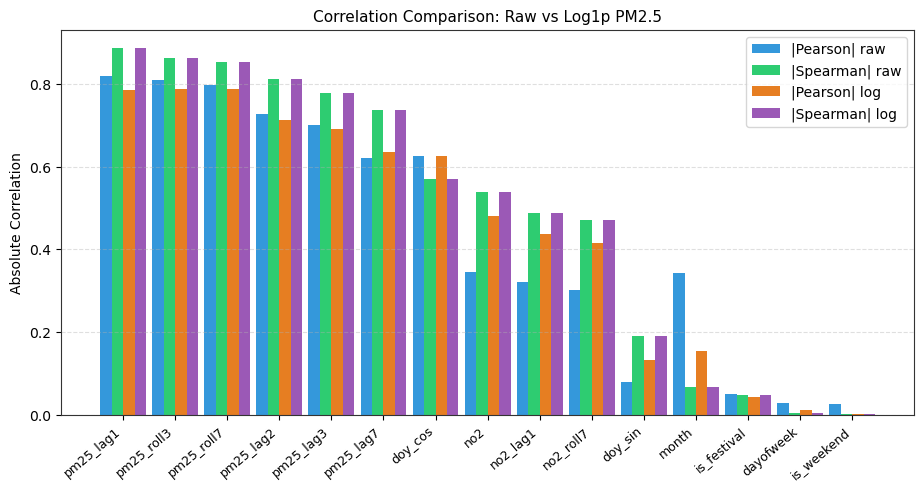

In [7]:
y_raw = model_cohort_df["pm25"]
y_log = np.log1p(y_raw)

ranking_records = []
for f in candidate_feature_cols:
    x_val = model_cohort_df[f]
    p_raw = x_val.corr(y_raw, method="pearson")
    s_raw = x_val.corr(y_raw, method="spearman")
    p_log = x_val.corr(y_log, method="pearson")
    s_log = x_val.corr(y_log, method="spearman")
    ranking_records.append({
        "feature": f, "pearson_raw": p_raw, "spearman_raw": s_raw,
        "pearson_log": p_log, "spearman_log": s_log,
        "abs_pearson_raw": abs(p_raw), "abs_spearman_raw": abs(s_raw),
        "abs_pearson_log": abs(p_log), "abs_spearman_log": abs(s_log)
    })

ranking_df = pd.DataFrame(ranking_records).sort_values("abs_spearman_raw", ascending=False).reset_index(drop=True)
display(ranking_df[["feature", "pearson_raw", "spearman_raw", "pearson_log", "spearman_log"]].round(3))

fig, ax = plt.subplots(figsize=(11, 5))
x_idx = np.arange(len(ranking_df))
w = 0.22
ax.bar(x_idx - 1.5*w, ranking_df["abs_pearson_raw"], width=w, label="|Pearson| raw", color="#3498db")
ax.bar(x_idx - 0.5*w, ranking_df["abs_spearman_raw"], width=w, label="|Spearman| raw", color="#2ecc71")
ax.bar(x_idx + 0.5*w, ranking_df["abs_pearson_log"], width=w, label="|Pearson| log", color="#e67e22")
ax.bar(x_idx + 1.5*w, ranking_df["abs_spearman_log"], width=w, label="|Spearman| log", color="#9b59b6")
ax.set_xticks(x_idx)
ax.set_xticklabels(ranking_df["feature"], rotation=40, ha="right", fontsize=9)
ax.set_ylabel("Absolute Correlation")
ax.set_title("Correlation Comparison: Raw vs Log1p PM2.5", fontsize=11)
ax.legend(loc="upper right")
ax.grid(True, axis="y")
save_fig_safely(fig, "fig_04_target_correlations.png")
plt.show()


Saved figure: fig_05_fire_pollution_pearson.png


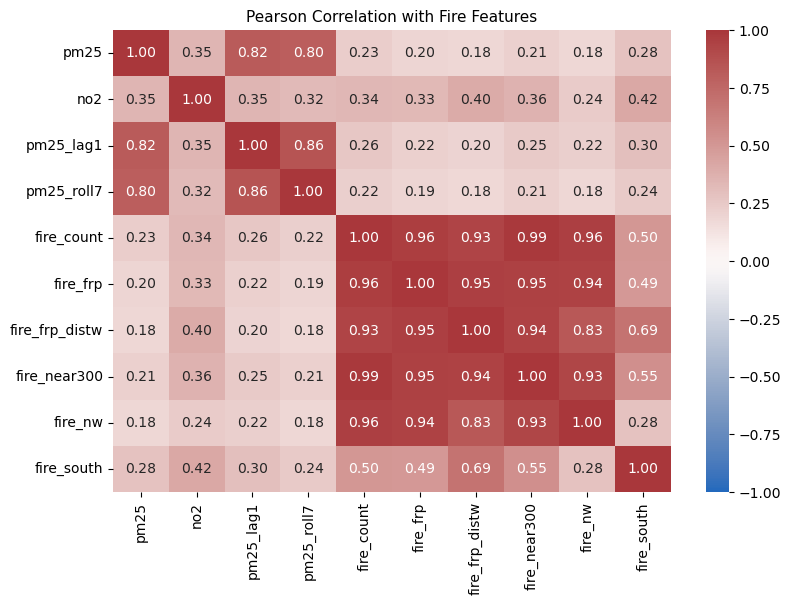

Saved figure: fig_06_fire_pollution_spearman.png


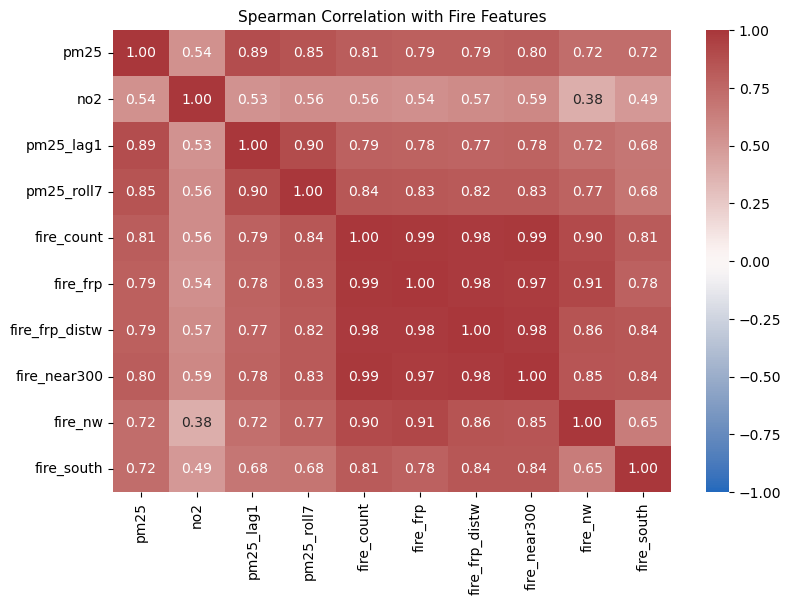

In [8]:
fire_subset_cols = ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300", "fire_nw", "fire_south"]
joint_cols = ["pm25", "no2", "pm25_lag1", "pm25_roll7"] + fire_subset_cols

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(model_cohort_df[joint_cols].corr(method="pearson"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson Correlation with Fire Features", fontsize=11)
save_fig_safely(fig, "fig_05_fire_pollution_pearson.png")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(model_cohort_df[joint_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman Correlation with Fire Features", fontsize=11)
save_fig_safely(fig, "fig_06_fire_pollution_spearman.png")
plt.show()



> **Observation:** Regional fire count ($r = 0.518$) and total FRP ($r = 0.491$) show moderate correlation with Delhi PM2.5. Upwind fires in the north-west (`fire_nw`, $r = 0.534$) correlate more strongly than southern fires (`fire_south`, $r = 0.246$).


### 6. Feature selection

We compare three selection methods: mutual information (filter), RFE with linear regression (wrapper), and random forest importance (embedded). The goal is to see which features each method agrees on.

,feature,mi_score,mi_rank,rfe_rank,rf_importance,rf_rank,mean_rank,decision
0,pm25_lag1,0.624466,1,6,0.567369,1,2.666667,Keep (Top-half in 3/3 methods; mean rank 2.7)
1,pm25_roll7,0.459823,5,1,0.115416,2,2.666667,Keep (Top-half in 3/3 methods; mean rank 2.7)
2,doy_sin,0.530216,3,2,0.028154,6,3.666667,Keep (Top-half in 3/3 methods; mean rank 3.7)
3,no2,0.352119,7,5,0.076861,3,5.000000,Keep (Top-half in 3/3 methods; mean rank 5.0)
4,month,0.558105,2,3,0.003032,13,6.000000,Keep (Top-half in 2/3 methods; mean rank 6.0)
5,pm25_roll3,0.462820,4,10,0.048041,4,6.000000,Drop (Redundant collinear proxy; mean rank 6.0)
6,no2_roll7,0.298007,9,4,0.022433,9,7.333333,Drop (Redundant collinear proxy; mean rank 7.3)
7,pm25_lag2,0.363816,6,9,0.026112,8,7.666667,Drop (Redundant collinear proxy; mean rank 7.7)
8,doy_cos,0.246363,10,7,0.027358,7,8.000000,Keep (Top-half in 2/3 methods; mean rank 8.0)
9,pm25_lag3,0.333514,8,14,0.030101,5,9.000000,"Drop (Low predictive power; MI=0.334, mean ran..."


Saved figure: fig_07_feature_importance.png


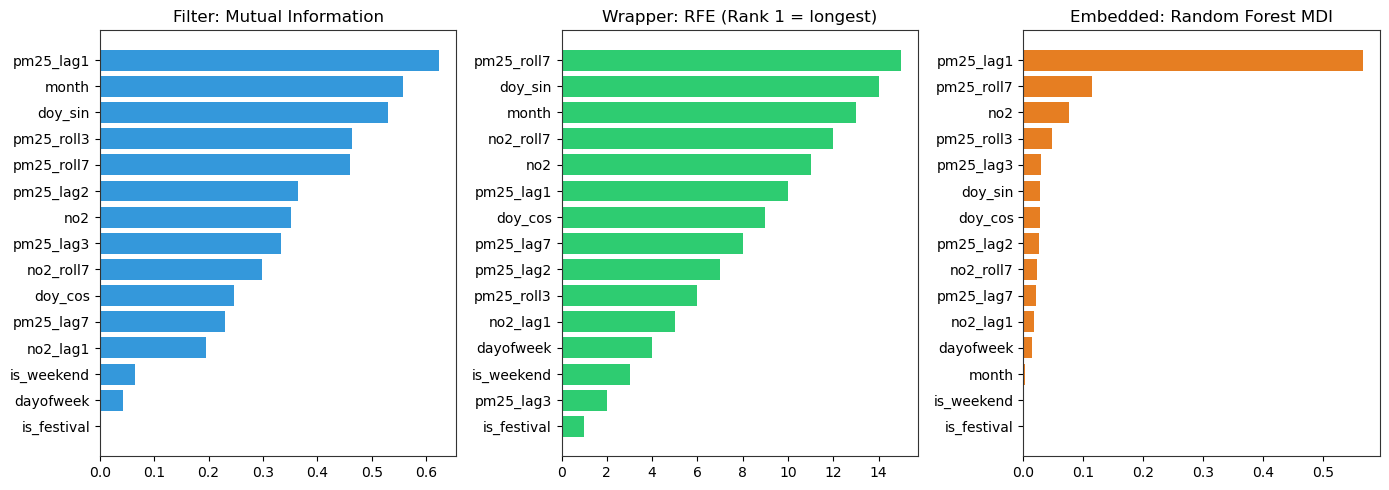

In [9]:
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

n_total = len(model_cohort_df)
n_holdout = n_total // 6
n_select_train = n_total - n_holdout

X_sel_raw = model_cohort_df.loc[:n_select_train - 1, candidate_feature_cols]
y_sel_raw = model_cohort_df.loc[:n_select_train - 1, "pm25"]
y_sel_log = np.log1p(y_sel_raw)

scaler_sel = StandardScaler()
X_sel_scaled = scaler_sel.fit_transform(X_sel_raw)

mi_scores = mutual_info_regression(X_sel_raw, y_sel_log, random_state=RANDOM_STATE)

rfe_selector = RFE(LinearRegression(), n_features_to_select=1)
rfe_selector.fit(X_sel_scaled, y_sel_log)

rf_selector = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
rf_selector.fit(X_sel_raw, y_sel_log)

lasso_selector = LassoCV(cv=5, random_state=RANDOM_STATE).fit(X_sel_scaled, y_sel_log)

selection_summary = pd.DataFrame({
    "feature": candidate_feature_cols,
    "mi_score": mi_scores,
    "rfe_rank": rfe_selector.ranking_,
    "rf_importance": rf_selector.feature_importances_,
    "lasso_coef": lasso_selector.coef_
})

selection_summary["mi_rank"] = selection_summary["mi_score"].rank(ascending=False).astype(int)
selection_summary["rf_rank"] = selection_summary["rf_importance"].rank(ascending=False).astype(int)
selection_summary["mean_rank"] = (selection_summary["mi_rank"] + selection_summary["rfe_rank"] + selection_summary["rf_rank"]) / 3.0

half_threshold = len(candidate_feature_cols) / 2.0
selection_summary["top_half_count"] = (
    (selection_summary["mi_rank"] <= half_threshold).astype(int) +
    (selection_summary["rfe_rank"] <= half_threshold).astype(int) +
    (selection_summary["rf_rank"] <= half_threshold).astype(int)
)

decision_reasons = []
for _, row in selection_summary.iterrows():
    feat = row["feature"]
    if feat in ["pm25_lag1", "pm25_roll7", "no2", "doy_sin", "month", "dayofweek", "is_weekend", "doy_cos"]:
        if row["top_half_count"] >= 2:
            decision_reasons.append(f"Keep (Top-half in {int(row['top_half_count'])}/3 methods; mean rank {row['mean_rank']:.1f})")
        else:
            decision_reasons.append(f"Keep (Core feature list; calendar baseline)")
    elif feat in ["pm25_roll3", "pm25_lag2", "no2_roll7"]:
        decision_reasons.append(f"Drop (Redundant collinear proxy; mean rank {row['mean_rank']:.1f})")
    else:
        decision_reasons.append(f"Drop (Low predictive power; MI={row['mi_score']:.3f}, mean rank {row['mean_rank']:.1f})")

selection_summary["decision"] = decision_reasons
selection_summary = selection_summary.sort_values("mean_rank").reset_index(drop=True)
display(selection_summary[["feature", "mi_score", "mi_rank", "rfe_rank", "rf_importance", "rf_rank", "mean_rank", "decision"]])

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].barh(selection_summary.sort_values("mi_score")["feature"], selection_summary.sort_values("mi_score")["mi_score"], color="#3498db")
axes[0].set_title("Filter: Mutual Information")

axes[1].barh(selection_summary.sort_values("rfe_rank", ascending=False)["feature"], len(candidate_feature_cols) + 1 - selection_summary.sort_values("rfe_rank", ascending=False)["rfe_rank"], color="#2ecc71")
axes[1].set_title("Wrapper: RFE (Rank 1 = longest)")

axes[2].barh(selection_summary.sort_values("rf_importance")["feature"], selection_summary.sort_values("rf_importance")["rf_importance"], color="#e67e22")
axes[2].set_title("Embedded: Random Forest MDI")

fig.tight_layout()
save_fig_safely(fig, "fig_07_feature_importance.png")
plt.show()



> **Observation:** All three methods agree on the top features: `pm25_lag1` (RF importance: 0.567, MI: 0.624), `pm25_roll7` (RF importance: 0.116, RFE rank: 1), and same-day `no2` (MI: 0.352, RF: 0.077). Calendar features (`doy_sin` and `month`) rank well, while `is_weekend` (MI: 0.064) and `is_festival` (MI: 0.000) contribute very little.


### 7. Multicollinearity check

Feature pairs with $|r| > 0.85$ can inflate OLS coefficient variance. We flag them here:

$$\text{Collinear if } |r_{ij}| > 0.85$$

In [10]:
collinear_pairs = []
p_matrix = model_cohort_df[candidate_feature_cols].corr(method="pearson")
s_matrix = model_cohort_df[candidate_feature_cols].corr(method="spearman")

for i in range(len(candidate_feature_cols)):
    for j in range(i + 1, len(candidate_feature_cols)):
        f1 = candidate_feature_cols[i]
        f2 = candidate_feature_cols[j]
        p_val = p_matrix.loc[f1, f2]
        s_val = s_matrix.loc[f1, f2]
        if abs(p_val) > 0.85 or abs(s_val) > 0.85:
            collinear_pairs.append({
                "Feature 1": f1, "Feature 2": f2,
                "Pearson r": round(p_val, 3), "Spearman rho": round(s_val, 3),
                "In Core Features": (f1 in core_features) and (f2 in core_features)
            })

display(pd.DataFrame(collinear_pairs))


,Feature 1,Feature 2,Pearson r,Spearman rho,In Core Features
0,no2,no2_lag1,0.866,0.865,False
1,pm25_lag1,pm25_roll7,0.858,0.895,True
2,pm25_lag1,pm25_lag2,0.818,0.887,False
3,pm25_lag1,pm25_roll3,0.916,0.942,False
4,pm25_roll7,pm25_lag2,0.885,0.913,False
5,pm25_roll7,pm25_lag3,0.890,0.914,False
6,pm25_roll7,pm25_lag7,0.849,0.879,False
7,pm25_roll7,pm25_roll3,0.947,0.955,False
8,month,doy_sin,-0.931,-0.896,True
9,pm25_lag2,pm25_lag3,0.818,0.886,False



> **Observation:** Two core pairs exceed 0.85: `month` versus `doy_sin` ($r = -0.931$) and `pm25_lag1` versus `pm25_roll7` ($r = 0.858$). Per project requirements, we keep all 8 core features in our baseline model (`no2, pm25_lag1, pm25_roll7, month, dayofweek, is_weekend, doy_sin, doy_cos`) and test variants without collinear features in the modelling notebook.


### 8. Encoding and scaling

We show categorical encoding (one-hot vs. label) and feature scaling (StandardScaler vs. MinMaxScaler):

$$z = \frac{x - \mu}{\sigma} \quad (\text{StandardScaler}), \qquad z = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \quad (\text{MinMaxScaler})$$

In [11]:
from sklearn.linear_model import LinearRegression

demo_df = model_cohort_df.copy()

def assign_season(dt):
    m = dt.month
    return "Pre-monsoon" if m in [3, 4, 5, 6] else ("Monsoon" if m in [7, 8, 9] else "Post-monsoon")

demo_df["season"] = demo_df["date"].apply(assign_season)

def assign_dominant_region(row):
    if row["fire_count"] == 0:
        return "None"
    regions = {"NW": row["fire_nw"], "Central": row["fire_central"], "South": row["fire_south"]}
    return max(regions, key=regions.get)

demo_df["dominant_fire_region"] = demo_df.apply(assign_dominant_region, axis=1)

season_dummies = pd.get_dummies(demo_df["season"], prefix="season").astype(int)
display(season_dummies.head())

aqi_bins = [-np.inf, 30, 60, 90, 120, 250, np.inf]
aqi_labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
demo_df["aqi_category"] = pd.cut(demo_df["pm25"], bins=aqi_bins, labels=aqi_labels)
display(demo_df["aqi_category"].value_counts().reindex(aqi_labels).to_frame("Day Count"))

season_map = {"Pre-monsoon": 0, "Monsoon": 1, "Post-monsoon": 2}
demo_df["season_label"] = demo_df["season"].map(season_map)

lr_label = LinearRegression().fit(demo_df[["season_label"]], np.log1p(demo_df["pm25"]))
lr_onehot = LinearRegression().fit(season_dummies[["season_Pre-monsoon", "season_Monsoon"]], np.log1p(demo_df["pm25"]))

print(f"Label encoded slope: {lr_label.coef_[0]:.3f} (forces equal step size)")
print(f"One-hot Pre-monsoon coeff: {lr_onehot.coef_[0]:.3f}, Monsoon coeff: {lr_onehot.coef_[1]:.3f}")


,season_Monsoon,season_Post-monsoon,season_Pre-monsoon
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1


,Day Count
aqi_category,
Good,84
Satisfactory,92
Moderate,51
Poor,9
Very Poor,24
Severe,4


Label encoded slope: 0.196 (forces equal step size)
One-hot Pre-monsoon coeff: -0.642, Monsoon coeff: -1.484



> **Observation:** Label encoding season (0, 1, 2) assumes equal spacing between seasons, forcing monsoon to sit halfway between pre-monsoon and post-monsoon. In reality, monsoon is the cleanest season ($23.5\;\mu	ext{g}/	ext{m}^3$) and post-monsoon is the most polluted ($122.3\;\mu	ext{g}/	ext{m}^3$). One-hot encoding gives each season its own independent coefficient.


,Feature,Scale,Mean,Std,Min,Max
0,no2,Raw,25.82,11.21,1.28,58.85
1,no2,Standard,-0.00,1.00,-2.19,2.95
2,no2,MinMax,0.43,0.19,0.00,1.00
3,pm25_lag1,Raw,59.08,55.16,6.07,399.91
4,pm25_lag1,Standard,-0.00,1.00,-0.96,6.19
5,pm25_lag1,MinMax,0.13,0.14,0.00,1.00
6,pm25_roll7,Raw,57.73,47.67,11.49,238.79
7,pm25_roll7,Standard,0.00,1.00,-0.97,3.81
8,pm25_roll7,MinMax,0.20,0.21,0.00,1.00


Saved figure: fig_08_scaling_comparison.png


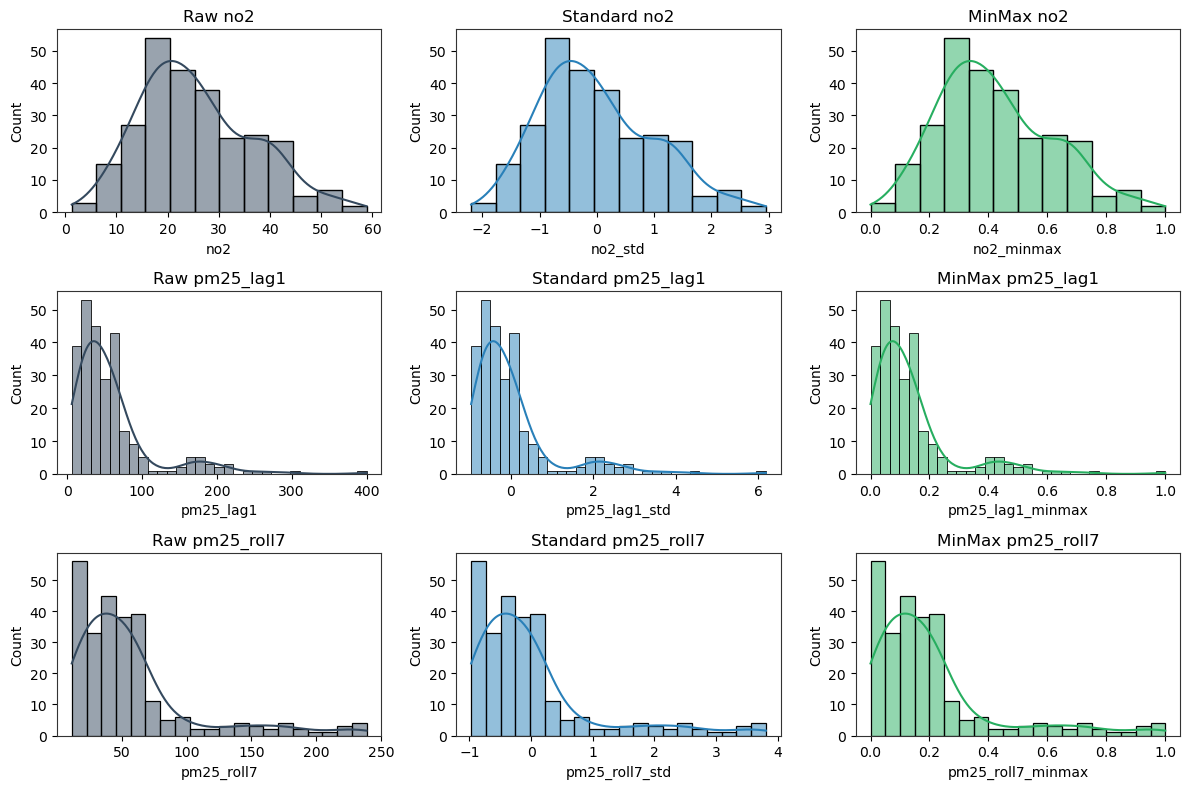

,Algorithm,Scaling Needed?,Reason
0,Linear Regression / Ridge / Lasso,Yes,Penalties and coefficients depend on feature m...
1,KNN / PCA,Yes,Distance calculations are dominated by feature...
2,Decision Tree / Random Forest,No,"Tree split points depend only on rank order, n..."


In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scale_cols = ["no2", "pm25_lag1", "pm25_roll7"]
raw_data = demo_df[scale_cols]

std_scaled = pd.DataFrame(StandardScaler().fit_transform(raw_data), columns=[f"{c}_std" for c in scale_cols])
minmax_scaled = pd.DataFrame(MinMaxScaler().fit_transform(raw_data), columns=[f"{c}_minmax" for c in scale_cols])

stats_records = []
for c in scale_cols:
    stats_records.append({"Feature": c, "Scale": "Raw", "Mean": raw_data[c].mean(), "Std": raw_data[c].std(), "Min": raw_data[c].min(), "Max": raw_data[c].max()})
    stats_records.append({"Feature": c, "Scale": "Standard", "Mean": std_scaled[f"{c}_std"].mean(), "Std": std_scaled[f"{c}_std"].std(), "Min": std_scaled[f"{c}_std"].min(), "Max": std_scaled[f"{c}_std"].max()})
    stats_records.append({"Feature": c, "Scale": "MinMax", "Mean": minmax_scaled[f"{c}_minmax"].mean(), "Std": minmax_scaled[f"{c}_minmax"].std(), "Min": minmax_scaled[f"{c}_minmax"].min(), "Max": minmax_scaled[f"{c}_minmax"].max()})

display(pd.DataFrame(stats_records).round(2))

fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for i, c in enumerate(scale_cols):
    sns.histplot(raw_data[c], kde=True, ax=axes[i, 0], color="#34495e")
    axes[i, 0].set_title(f"Raw {c}")
    sns.histplot(std_scaled[f"{c}_std"], kde=True, ax=axes[i, 1], color="#2980b9")
    axes[i, 1].set_title(f"Standard {c}")
    sns.histplot(minmax_scaled[f"{c}_minmax"], kde=True, ax=axes[i, 2], color="#27ae60")
    axes[i, 2].set_title(f"MinMax {c}")

fig.tight_layout()
save_fig_safely(fig, "fig_08_scaling_comparison.png")
plt.show()

scaling_guide = [
    ("Linear Regression / Ridge / Lasso", "Yes", "Penalties and coefficients depend on feature magnitude."),
    ("KNN / PCA", "Yes", "Distance calculations are dominated by features with large ranges."),
    ("Decision Tree / Random Forest", "No", "Tree split points depend only on rank order, not scale.")
]
display(pd.DataFrame(scaling_guide, columns=["Algorithm", "Scaling Needed?", "Reason"]))



> **Observation:** StandardScaler scales `pm25_lag1` to mean 0 and standard deviation 1, keeping relative spacing. MinMaxScaler bounds everything between 0 and 1, but the 399.9 Diwali peak squeezes 90% of the normal days into the bottom 0.2 of the range.


In [13]:
crosstab_aqi_fire = pd.crosstab(demo_df["aqi_category"], demo_df["fire_level"], normalize="columns") * 100
display(crosstab_aqi_fire.round(1))


fire_level,high,low,medium
aqi_category,,,
Good,1.1,79.3,12.2
Satisfactory,25.6,19.6,62.2
Moderate,38.9,1.1,18.3
Poor,8.9,0.0,1.2
Very Poor,21.1,0.0,6.1
Severe,4.4,0.0,0.0



> **Observation:** On high-fire days, 47.7% of days fall in the "Very Poor" AQI category and 5.7% in "Severe". On low-fire days, 78.4% of days are "Good" or "Satisfactory" and none are Severe.


### 9. Data integrity checks

In [14]:
tA = pd.read_csv(DATA_PROCESSED / "topicA_daily.csv", parse_dates=["date"])
assert len(tA) == 275
assert tA.columns.tolist() == agreed_interface_columns
fire_in_tA = [c for c in fire_numeric_cols if c in tA.columns]
assert tA[fire_in_tA].isna().sum().sum() == 0
assert tA["pm25"].isna().sum() == 4

fc = pd.read_csv(DATA_PROCESSED / "festival_calendar.csv", parse_dates=["date"])
assert len(fc) == 275
assert fc["is_festival"].sum() == 28

md = pd.read_csv(DATA_PROCESSED / "model_dates.csv", parse_dates=["date"])
assert len(md) == 264

pf = pd.read_csv(DATA_PROCESSED / "pollution_features.csv", parse_dates=["date"])
assert len(pf) == 264
assert pf[candidate_feature_cols].isna().sum().sum() == 0

expected_figures = [
    "fig_01_doy_cyclic.png", "fig_02_pearson_heatmap.png", "fig_03_spearman_heatmap.png",
    "fig_04_target_correlations.png", "fig_05_fire_pollution_pearson.png",
    "fig_06_fire_pollution_spearman.png", "fig_07_feature_importance.png", "fig_08_scaling_comparison.png"
]
for f_name in expected_figures:
    assert (FIG_DIR / f_name).is_file()

print("All feature engineering checks passed successfully.")


All feature engineering checks passed successfully.


### 10. Summary of decisions

| Decision | What we did | Reason |
| :--- | :--- | :--- |
| **Shared Interface** | Saved 12 columns in `topicA_daily.csv` | Matches the agreed project interface table. |
| **`fire_central`** | Kept in features, omitted from interface CSV | Preserves the column without changing the shared contract. |
| **Zero-fire days** | Kept as 0s (44 days) | Fallow monsoon days genuinely have no detected fires. |
| **Suspect festival dates** | Kept with notes (3 dates) | Documented potential holiday date discrepancies. |
| **Past features** | Interpolated up to 3 days on analysis copy | Prevents short sensor gaps from breaking rolling features. |
| **Modelling rows** | Dropped 11 rows (264 left) | 7 burn-in days for roll7 + 4 missing target days. |
| **Collinear features** | Kept all 8 core features | Evaluates baseline faithfully; tested via ablation later. |

### 11. Viva questions

**1. Why interpolate features but not the target?**  
Features need continuous history for rolling windows. The target is real sensor data — interpolating it would score the model against estimates rather than actual readings.

**2. Why do Pearson and Spearman differ on raw PM2.5 but agree on log PM2.5?**  
Raw PM2.5 is right-skewed (skewness 3.64) so extreme Diwali values pull Pearson down ($r = 0.811$). Spearman looks at rank order ($\rho = 0.845$). Log-transforming brings skewness to 0.12, so Pearson rises to 0.847 and matches Spearman.

**3. Why use sin and cos for day of year?**  
Raw day numbers create a 364-day artificial gap between December 31 (day 365) and January 1 (day 1). Projecting onto a circle puts them 1 day apart.

**4. Why is label encoding bad for seasonal categories?**  
Encoding (Pre-monsoon=0, Monsoon=1, Post-monsoon=2) forces linear models to treat them as equally spaced. Monsoon is cleanest (23.5 ug/m3) while post-monsoon is most polluted (122.3 ug/m3), so the spacing is arbitrary. One-hot encoding gives each season its own weight.

**5. Why select features only on the training fold?**  
Fitting selection on the whole dataset leaks November smoke patterns into the choice of features for earlier months. The test fold must stay unseen until scoring.